# Lesson 0 — Setup and the big picture

⏱ **Duration:** ~15 min &nbsp;|&nbsp; 📚 **Builds on:** nothing &nbsp;|&nbsp; 💻 **Runs on:** a laptop CPU

**By the end of this lesson you will be able to:**

- explain in one sentence what a language model does
- name the five stages of the pipeline (data → tokens → model → training → sampling)
- check that your environment works and measure how fast your CPU trains

> 🎤 *Teaching tip:* run the cells in order; every code cell is short enough to be explained live.

## 1. What is a language model?

A language model answers one question, over and over:

> **Given the words so far, which word is likely to come next?**

Training teaches it the statistics of a text. Generation is just asking that question repeatedly
and appending the answer. A "large" language model is the same idea with a bigger network and far more
text. In this course we build a **small** one (~1M parameters) that trains in **10 minutes on a CPU**.

```
 raw text ──► tokenizer ──► token ids ──► GPT model ──► next-token probabilities
 (lesson 1)    (lesson 2)                 (lesson 3)         │
                                                   training (lesson 4)   sampling (lesson 5)
                                                   evaluation (lesson 6) experiments (lesson 7)
```

## 2. Course map

| # | Lesson | Question it answers |
|---|--------|---------------------|
| 0 | Setup (this one) | What are we building, does my machine work? |
| 1 | Data | What text do we train on and how do we feed it? |
| 2 | Tokenization | How does text become numbers? |
| 3 | Model architecture | What is inside a GPT? |
| 4 | Training | How does the model learn? |
| 5 | Inference | How do we turn probabilities into text? |
| 6 | Evaluation | How good is it, really? |
| 7 | Experiments | What happens if we change the model? |
| 8 | The 10-minute LLM | The complete recipe end to end |
| 9 | Toolbox | CLI, checkpoints, GPU, troubleshooting |
| 10 | Wrap-up | Glossary, quiz, project ideas |

## 3. The code you will use

Everything lives in the small `myllm` package (one file per concept):

| file | concept |
|------|---------|
| `tokenizer.py` | words ↔ ids |
| `data.py` | corpus, split, batches |
| `model.py` | the GPT |
| `train.py` | training loop |
| `generate.py` | sampling |
| `evaluate.py` | perplexity and accuracy |
| `plots.py` | charts |

## 4. Check your environment

In [1]:
import sys, warnings
from pathlib import Path

warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))  # lets us `import myllm` without installing it

import torch
import matplotlib.pyplot as plt

%matplotlib inline
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})
torch.set_num_threads(4)
DATA = ROOT / "data" / "raw"       # training text lives here
MODELS = ROOT / "models"           # checkpoints are written here

In [2]:
import platform, os
print("python   :", platform.python_version())
print("torch    :", torch.__version__)
print("cpu cores:", os.cpu_count())
print("cuda     :", torch.cuda.is_available(), "(not needed — we train on CPU)")
import myllm
print("myllm    :", myllm.__version__)

python   : 3.13.5
torch    : 2.14.0+cu130
cpu cores: 8
cuda     : False (not needed — we train on CPU)
myllm    : 0.2.0


## 5. Is the training text there?

In [3]:
files = sorted(DATA.glob("*.txt"))
for f in files:
    print(f"{f.name:45s} {f.stat().st_size / 1e6:6.2f} MB")
assert files, "No text found: run  `python scripts/download_full_texts.py`  from the project root"

bible_kjv_full.txt                              4.33 MB
mastering_bitcoin_third_edition.txt             0.90 MB


## 6. How fast is *your* machine?

Training time is `steps × time-per-step`. Let's **measure** the time per training step for the
three presets so we know what 10 minutes buys us. (We use random tokens — speed does not depend on the data.)

In [4]:
import time
from myllm.model import GPT, GPTConfig
from myllm.train import PRESETS

rows = []
for name, (kw, defaults, minutes) in PRESETS.items():
    model = GPT(GPTConfig(vocab_size=defaults["vocab_size"], **kw))
    opt = torch.optim.AdamW(model.parameters())
    bs, blk = defaults["batch_size"], kw["block_size"]
    x = torch.randint(0, defaults["vocab_size"], (bs, blk))
    for i in range(8):
        if i == 3:
            t0 = time.time()
        _, loss = model(x, x); opt.zero_grad(); loss.backward(); opt.step()
    dt = (time.time() - t0) / 5
    rows.append((name, model.num_params(), dt * 1000, bs * blk / dt, minutes, int(minutes * 60 / dt)))

print(f"{'preset':8s} {'params':>10s} {'ms/step':>8s} {'tok/s':>8s} {'budget':>7s} {'steps in budget':>16s}")
for n, p, ms, tps, m, st in rows:
    print(f"{n:8s} {p:10,d} {ms:8.0f} {tps:8.0f} {m:6.0f}m {st:16,d}")

preset       params  ms/step    tok/s  budget  steps in budget
tiny        230,144       32    15787      1m            1,849
fast        786,944      104     7387      3m            1,731
default   1,115,264      156     6558     10m            3,842


> ⚠️ The projection is optimistic: a real run also spends time on validation and shares the CPU with other programs, so expect ~30 % fewer steps.

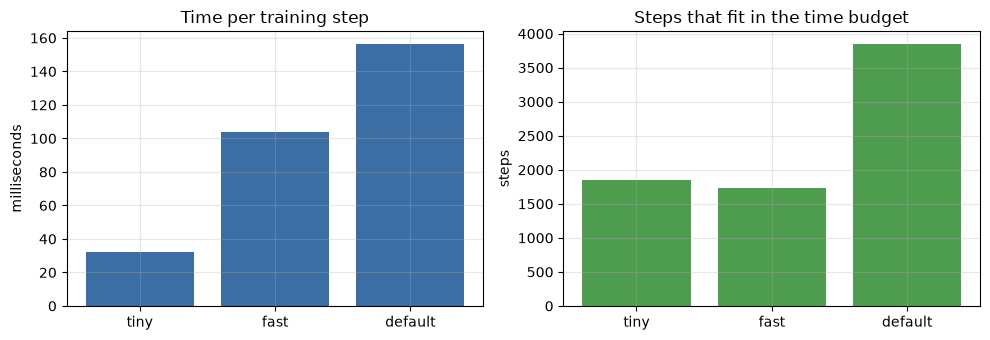

In [5]:
names = [r[0] for r in rows]
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].bar(names, [r[2] for r in rows], color="#3b6ea5"); ax[0].set(title="Time per training step", ylabel="milliseconds")
ax[1].bar(names, [r[5] for r in rows], color="#4f9d4f"); ax[1].set(title="Steps that fit in the time budget", ylabel="steps")
plt.tight_layout()

---
## ✅ Key takeaways

- A language model predicts the next token; generation repeats that prediction.
- The pipeline is: data → tokenizer → model → training → sampling → evaluation.
- On a CPU the budget (minutes) and the model size together decide how many steps we get.

## 🧪 Exercises

1. Re-run the benchmark with `torch.set_num_threads(1)` and then `8`. Which is fastest on your machine? Why might more threads not help?
2. How many training steps would the `default` preset get in 3 minutes instead of 10?

## ➡️ Next

**Lesson 1 — Data:** what text we train on and how we prepare it.